# V6.5-17a — Kiểm tra SAM thắt box (rule H)
**SAM** (Segment Anything, Meta) = model phân đoạn: đưa vào ảnh + 1 box gợi ý → trả về **mask** (pixel nào thuộc vật).
Lấy khung bao nhỏ nhất của mask → box ôm sát vật. Ta dùng nó để thắt box GT bị lỏng.

- Chỉ áp cho **insulator / foreign_object**. bird_nest đã thử nhưng bỏ: SAM cắt mất cành ở rìa tổ, box GT thường đúng hơn. Với broken / flashover / strand (vùng lỗi *trên* vật) SAM ôm cả bát sứ / cả sợi dây → không dùng.
- Chỉ nhận khi box SAM **nằm trong** box GT (chỉ thu nhỏ, cho lệch 2%) và 0.5 ≤ IoU(GT, SAM) < 0.85
  (≥ 0.85: GT đã sát; < 0.5: SAM chỉ lấy 1 phần vật, ví dụ 1 bát sứ).
- Màu: **đỏ** = GT cũ, **xanh lá** = box SAM, mask tô xanh mờ.


In [1]:
# 1. CONFIG
from pathlib import Path
import random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import SAM

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next(p for p in candidates if (p / "pyproject.toml").is_file() and (p / "legacy/notebooks/v6p5").is_dir())
DATASET = PROJECT.parent / "datasets/v6p5_6cls_v2"  # nhãn trước khi thắt
SAM_CSV = PROJECT / "data/label_audit/sam_tighten/sam_boxes.csv"
NAMES = ["insulator", "insulator_broken", "insulator_flashover", "bird_nest", "foreign_object", "broken_strand"]
sam = SAM("sam2.1_b.pt")  # tự tải ~155 MB lần đầu; chạy được cả CPU (~1 s/ảnh) và GPU

def accepted(r):
    """Đúng điều kiện rule H trong scripts/label_audit_build.py."""
    inside = (r.sx - r.sw / 2 >= r.x - r.w / 2 - 0.02 * r.w and r.sx + r.sw / 2 <= r.x + r.w / 2 + 0.02 * r.w and
              r.sy - r.sh / 2 >= r.y - r.h / 2 - 0.02 * r.h and r.sy + r.sh / 2 <= r.y + r.h / 2 + 0.02 * r.h)
    return inside and 0.5 <= r.iou < 0.85 and r.class6 in (0, 4)

def xyxy(x, y, w, h, W, H):
    return [(x - w / 2) * W, (y - h / 2) * H, (x + w / 2) * W, (y + h / 2) * H]

def show(ax, img, gt, sb=None, mask=None, title="", pad=0.5):
    ax.imshow(img)
    if mask is not None:
        ax.imshow(np.ma.masked_where(~mask, mask), alpha=0.35, cmap="winter")
    for b, col in [(gt, "red"), (sb, "lime")]:
        if b is not None:
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec=col, lw=2))
    bw, bh = gt[2] - gt[0], gt[3] - gt[1]  # zoom quanh box
    ax.set_xlim(max(0, gt[0] - pad * bw), min(img.width, gt[2] + pad * bw))
    ax.set_ylim(min(img.height, gt[3] + pad * bh), max(0, gt[1] - pad * bh))
    ax.set_title(title, fontsize=8); ax.axis("off")


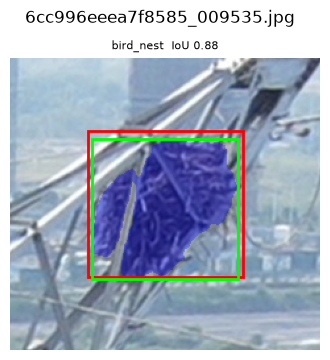

In [2]:
# 2. THỬ SAM TRỰC TIẾP trên 1 ảnh: mỗi box GT → mask + box SAM (đổi IMAGE / SPLIT để thử ảnh khác)
SPLIT = "train"
IMAGE = None  # None = chọn ngẫu nhiên 1 ảnh có insulator / bird_nest / foreign_object
if IMAGE is None:
    IMAGE = random.choice([f.stem for f in (DATASET / "labels" / SPLIT).glob("*.txt")
                           if any(l.split()[0] in "034" for l in f.read_text().splitlines() if l.strip())])
img_path = next((DATASET / "images" / SPLIT).glob(IMAGE + ".*"))
img = Image.open(img_path).convert("RGB"); W, H = img.size
gts = [(int(l.split()[0]), *map(float, l.split()[1:])) for l in (DATASET / "labels" / SPLIT / (IMAGE + ".txt")).read_text().splitlines() if l.strip()]
boxes = [xyxy(*g[1:], W, H) for g in gts]
masks = sam(img, bboxes=boxes, verbose=False)[0].masks.data.cpu().numpy() > 0.5

fig, axs = plt.subplots(1, len(gts), figsize=(4 * len(gts), 4), squeeze=False)
for ax, (c, *_), gt, mk in zip(axs[0], gts, boxes, masks):
    ys, xs = np.where(mk)
    sb = [xs.min(), ys.min(), xs.max() + 1, ys.max() + 1]
    ix = max(0, min(gt[2], sb[2]) - max(gt[0], sb[0])) * max(0, min(gt[3], sb[3]) - max(gt[1], sb[1]))
    iou = ix / ((gt[2] - gt[0]) * (gt[3] - gt[1]) + (sb[2] - sb[0]) * (sb[3] - sb[1]) - ix)
    show(ax, img, gt, sb, mk, f"{NAMES[c]}  IoU {iou:.2f}")
fig.suptitle(img_path.name); plt.show()


In [3]:
# 3. XEM KẾT QUẢ CHẠY HÀNG LOẠT (sam_boxes.csv): bao nhiêu box sẽ bị thắt, gap trước/sau
df = pd.read_csv(SAM_CSV)
df["cls"] = df.class6.map(dict(enumerate(NAMES)))
df["accept"] = df.apply(accepted, axis=1)
df["gap"] = 1 - df.iou  # gap giữa GT cũ và box ôm sát
print(f"{len(df)} box đã chạy SAM | {df.accept.sum()} box sẽ thay ({df.accept.mean():.1%})")
display(df.groupby(["split", "cls"]).agg(boxes=("accept", "size"), thay=("accept", "sum"),
                                         gap_tb=("gap", "mean"), gap_gt_0_3=("gap", lambda g: (g > 0.3).mean())).round(3))


14009 box đã chạy SAM | 2232 box sẽ thay (15.9%)


boxes  thay  gap_tb  gap_gt_0_3
split     cls                                            
train     bird_nest        6144   595   0.176       0.089
          foreign_object    953   453   0.255       0.376
          insulator        6721  1141   0.205       0.222
val_clean bird_nest          89    14   0.166       0.045
          foreign_object      7     2   0.151       0.143
          insulator          95    27   0.222       0.326

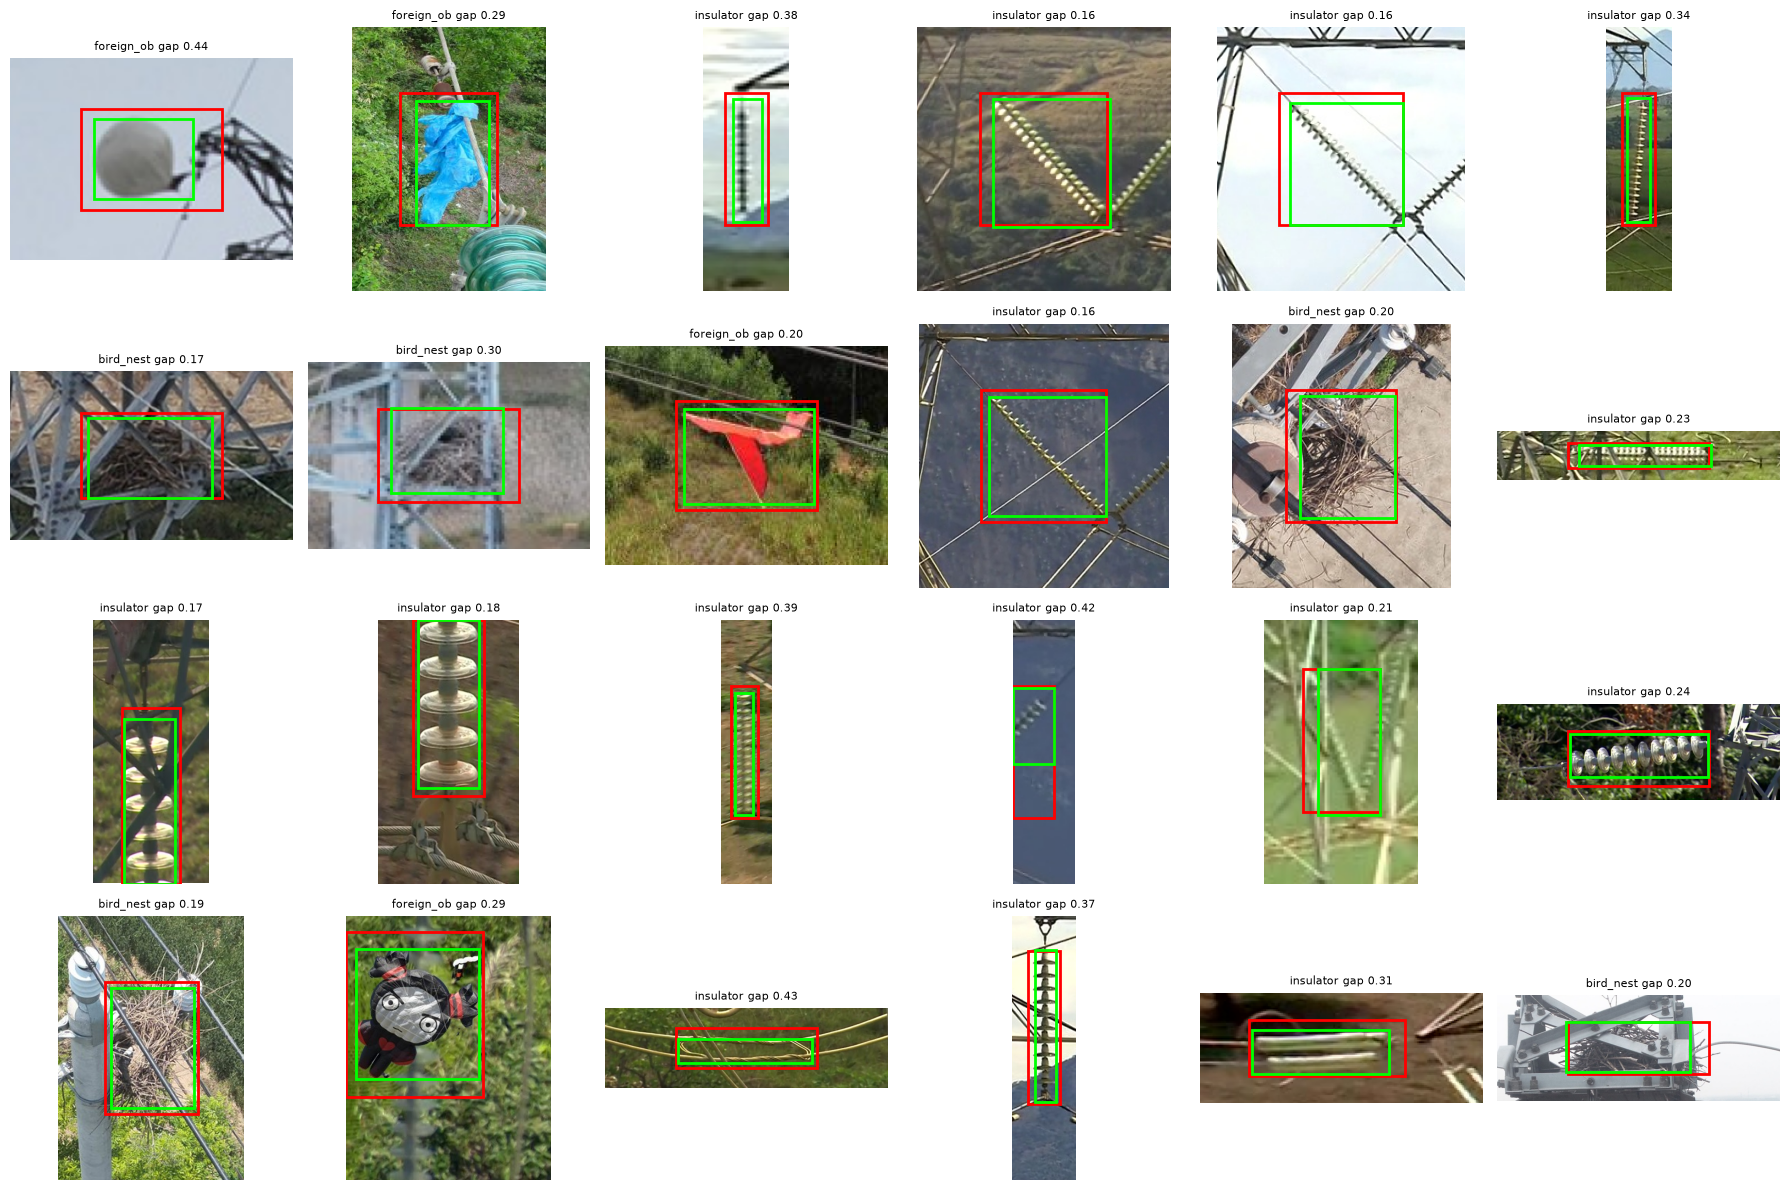

In [4]:
# 4. CONTACT SHEET: ngẫu nhiên N box được thay (đỏ = GT cũ, xanh = box mới) — chạy lại để xem mẫu khác
N, CLASS = 24, None  # CLASS = "bird_nest" / "insulator" / "foreign_object" để lọc
pick = df[df.accept & ((df.cls == CLASS) if CLASS else True)].sample(N)
fig, axs = plt.subplots(4, 6, figsize=(18, 12))
for ax, r in zip(axs.flat, pick.itertuples()):
    im = Image.open(next((DATASET / "images" / r.split).glob(Path(r.image).stem + ".*"))).convert("RGB")
    show(ax, im, xyxy(r.x, r.y, r.w, r.h, *im.size), xyxy(r.sx, r.sy, r.sw, r.sh, *im.size),
         title=f"{r.cls[:10]} gap {r.gap:.2f}")
plt.tight_layout(); plt.show()
